In [1]:
%pip install pandas numpy datasketch matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datasketch import MinHash, MinHashLSH
from itertools import combinations
import re

In [ ]:
documents = {
    "D1": "Machine learning helps computers learn patterns from data.",
    "D2": "Machine learning allows computers to identify patterns in data.",
    "D3": "Deep learning is a branch of machine learning using neural networks.",
    "D4": "Cooking recipes explain how to prepare delicious meals.",
    "D5": "Neural networks are used in deep learning and artificial intelligence."
}

df = pd.DataFrame({
    "Document ID": list(documents.keys()),
    "Text": list(documents.values())
})

display(df)
# Create sample documents

,Document ID,Text
0,D1,Machine learning helps computers learn pattern...
1,D2,Machine learning allows computers to identify ...
2,D3,Deep learning is a branch of machine learning ...
3,D4,Cooking recipes explain how to prepare delicio...
4,D5,Neural networks are used in deep learning and ...


In [ ]:
def generate_shingles(text, k=2):
    words = re.findall(r"\b\w+\b", text.lower())
    if len(words) < k:
        return set()
    return {" ".join(words[i:i + k]) for i in range(len(words) - k + 1)}

k = 2
shingles = {
    doc_id: generate_shingles(text, k)
    for doc_id, text in documents.items()
}

for doc_id, shingle_set in shingles.items():
    print(f"{doc_id}: {shingle_set}")
    # Generate word shingles
    # A shingle is a sequence of k consecutive words. Here, k = 2 by default

D1: {'learning helps', 'from data', 'helps computers', 'computers learn', 'machine learning', 'learn patterns', 'patterns from'}
D2: {'allows computers', 'patterns in', 'in data', 'computers to', 'to identify', 'learning allows', 'identify patterns', 'machine learning'}
D3: {'using neural', 'of machine', 'deep learning', 'learning using', 'learning is', 'is a', 'branch of', 'machine learning', 'neural networks', 'a branch'}
D4: {'cooking recipes', 'prepare delicious', 'delicious meals', 'recipes explain', 'explain how', 'how to', 'to prepare'}
D5: {'are used', 'learning and', 'in deep', 'and artificial', 'networks are', 'deep learning', 'artificial intelligence', 'used in', 'neural networks'}


In [ ]:
def jaccard_similarity(set_a, set_b):
    union = set_a | set_b
    if not union:
        return 1.0
    return len(set_a & set_b) / len(union)

pair_results = []
for doc_a, doc_b in combinations(documents.keys(), 2):
    score = jaccard_similarity(shingles[doc_a], shingles[doc_b])
    pair_results.append({
        "Document 1": doc_a,
        "Document 2": doc_b,
        "Jaccard Similarity": round(score, 3)
    })

jaccard_df = pd.DataFrame(pair_results).sort_values(
    "Jaccard Similarity", ascending=False
)
display(jaccard_df)
# Calculate Jaccard Similarity
# Jaccard Similarity = size of intersection / size of union

,Document 1,Document 2,Jaccard Similarity
8,D3,D5,0.118
0,D1,D2,0.071
1,D1,D3,0.062
4,D2,D3,0.059
3,D1,D5,0.000
2,D1,D4,0.000
5,D2,D4,0.000
6,D2,D5,0.000
7,D3,D4,0.000
9,D4,D5,0.000


In [ ]:
NUM_PERM = 128

minhashes = {}
for doc_id, shingle_set in shingles.items():
    mh = MinHash(num_perm=NUM_PERM)
    for shingle in shingle_set:
        mh.update(shingle.encode("utf-8"))
    minhashes[doc_id] = mh

for doc_id, mh in minhashes.items():
    print(f"{doc_id}: generated MinHash signature with {len(mh.hashvalues)} values")
    # Generate MinHash signatures

D1: generated MinHash signature with 128 values
D2: generated MinHash signature with 128 values
D3: generated MinHash signature with 128 values
D4: generated MinHash signature with 128 values
D5: generated MinHash signature with 128 values


In [ ]:
threshold = 0.3

lsh = MinHashLSH(threshold=threshold, num_perm=NUM_PERM)
for doc_id, mh in minhashes.items():
    lsh.insert(doc_id, mh)

print("LSH index created successfully.")

for doc_id, mh in minhashes.items():
    candidates = sorted(lsh.query(mh))
    similar = [candidate for candidate in candidates if candidate != doc_id]
    print(f"{doc_id} -> {similar}")
    # Build the LSH index and query similar documents

LSH index created successfully.
D1 -> []
D2 -> []
D3 -> []
D4 -> []
D5 -> []


In [ ]:
comparison = []

for doc_a, doc_b in combinations(documents.keys(), 2):
    exact = jaccard_similarity(shingles[doc_a], shingles[doc_b])
    estimated = minhashes[doc_a].jaccard(minhashes[doc_b])
    comparison.append({
        "Document 1": doc_a,
        "Document 2": doc_b,
        "Exact Jaccard": round(exact, 3),
        "MinHash Estimate": round(estimated, 3)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)
# Compare exact and estimated similarity

,Document 1,Document 2,Exact Jaccard,MinHash Estimate
0,D1,D2,0.071,0.055
1,D1,D3,0.062,0.062
2,D1,D4,0.000,0.000
3,D1,D5,0.000,0.000
4,D2,D3,0.059,0.055
5,D2,D4,0.000,0.000
6,D2,D5,0.000,0.000
7,D3,D4,0.000,0.000
8,D3,D5,0.118,0.094
9,D4,D5,0.000,0.000


### Assignment 1: Similarity between two documents

In [9]:
doc_a, doc_b = "D1", "D2"
score = jaccard_similarity(shingles[doc_a], shingles[doc_b])
print(f"Jaccard Similarity between {doc_a} and {doc_b}: {score:.3f}")

Jaccard Similarity between D1 and D2: 0.071


### Assignment 2: Change the shingle size

In [10]:
shingle_size_results = []

for size in [1, 2, 3]:
    sets_for_size = {
        doc_id: generate_shingles(text, size)
        for doc_id, text in documents.items()
    }
    score = jaccard_similarity(sets_for_size["D1"], sets_for_size["D2"])
    shingle_size_results.append({
        "Shingle Size": size,
        "D1 vs D2 Jaccard Similarity": round(score, 3)
    })

display(pd.DataFrame(shingle_size_results))

,Shingle Size,D1 vs D2 Jaccard Similarity
0,1,0.417
1,2,0.071
2,3,0.000


### Assignment 3: Add a new document and query LSH

In [11]:
new_id = "D6"
new_text = "Machine learning and neural networks find useful patterns in data."
new_shingles = generate_shingles(new_text, k)

new_mh = MinHash(num_perm=NUM_PERM)
for shingle in new_shingles:
    new_mh.update(shingle.encode("utf-8"))

# Query the existing index before inserting the new document.
candidates = sorted(lsh.query(new_mh))
print("Similar documents found by LSH:", candidates)

# Show exact Jaccard scores against all existing documents.
for doc_id, shingle_set in shingles.items():
    score = jaccard_similarity(new_shingles, shingle_set)
    print(f"{new_id} vs {doc_id}: Jaccard Similarity = {score:.3f}")

# Add the new document to the index for future queries.
lsh.insert(new_id, new_mh)
documents[new_id] = new_text
shingles[new_id] = new_shingles
minhashes[new_id] = new_mh

Similar documents found by LSH: []
D6 vs D1: Jaccard Similarity = 0.067
D6 vs D2: Jaccard Similarity = 0.214
D6 vs D3: Jaccard Similarity = 0.118
D6 vs D4: Jaccard Similarity = 0.000
D6 vs D5: Jaccard Similarity = 0.125


### Assignment 4: Compare different LSH thresholds

In [12]:
threshold_results = []

for threshold_value in [0.3, 0.5, 0.7]:
    index = MinHashLSH(threshold=threshold_value, num_perm=NUM_PERM)
    for doc_id, mh in minhashes.items():
        index.insert(doc_id, mh)

    candidate_pairs = set()
    for doc_id, mh in minhashes.items():
        for match in index.query(mh):
            if match != doc_id:
                candidate_pairs.add(tuple(sorted((doc_id, match))))

    threshold_results.append({
        "LSH Threshold": threshold_value,
        "Candidate Document Pairs": len(candidate_pairs),
        "Pairs": sorted(candidate_pairs)
    })

for result in threshold_results:
    print(f"Threshold: {result['LSH Threshold']}")
    print(f"Candidate pairs found: {result['Candidate Document Pairs']}")
    print(result["Pairs"])
    print()

Threshold: 0.3
Candidate pairs found: 0
[]

Threshold: 0.5
Candidate pairs found: 0
[]

Threshold: 0.7
Candidate pairs found: 0
[]



### Assignment 5: Compare direct comparison and LSH

In [13]:
number_of_documents = len(documents)
all_pairs = number_of_documents * (number_of_documents - 1) // 2

print("Number of documents:", number_of_documents)
print("Direct pairwise comparisons required:", all_pairs)
print("LSH checks candidate buckets rather than calculating exact Jaccard")
print("similarity for every pair. Its actual speed depends on dataset size,")
print("threshold, and how many candidates are returned.")

Number of documents: 6
Direct pairwise comparisons required: 15
LSH checks candidate buckets rather than calculating exact Jaccard
similarity for every pair. Its actual speed depends on dataset size,
threshold, and how many candidates are returned.


## Visualize the Jaccard Similarity Matrix

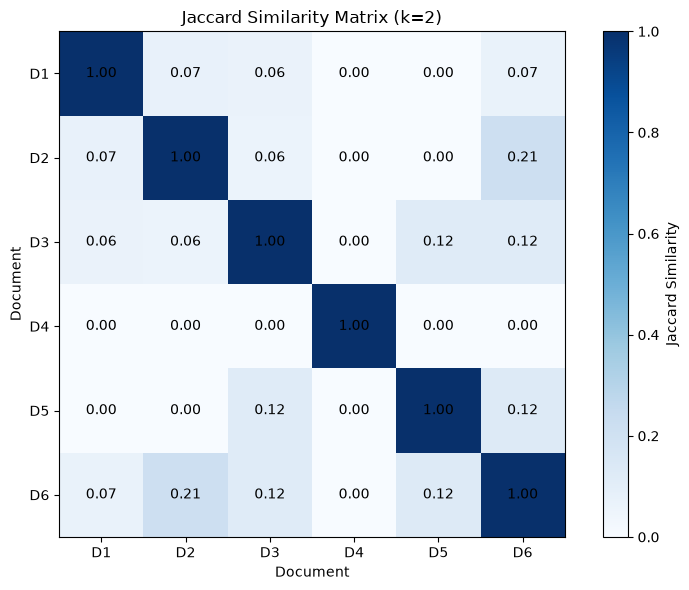

In [14]:
doc_ids = list(documents.keys())
similarity_matrix = np.zeros((len(doc_ids), len(doc_ids)))

for i, doc_a in enumerate(doc_ids):
    for j, doc_b in enumerate(doc_ids):
        similarity_matrix[i, j] = jaccard_similarity(
            shingles[doc_a], shingles[doc_b]
        )

plt.figure(figsize=(8, 6))
plt.imshow(similarity_matrix, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Jaccard Similarity")
plt.xticks(range(len(doc_ids)), doc_ids)
plt.yticks(range(len(doc_ids)), doc_ids)
plt.xlabel("Document")
plt.ylabel("Document")
plt.title(f"Jaccard Similarity Matrix (k={k})")

for i in range(len(doc_ids)):
    for j in range(len(doc_ids)):
        plt.text(j, i, f"{similarity_matrix[i, j]:.2f}",
                 ha="center", va="center")

plt.tight_layout()
plt.show()